In [498]:
!pip install fastbook

In [499]:
import fastbook
fastbook.setup_book()
from fastbook import *

In [500]:
from fastai.collab import *
from fastai.tabular.all import *

In [501]:
data_folder = Path("restaurant-data")
list(data_folder.ls())

[Path('restaurant-data/userprofile.csv'),
 Path('restaurant-data/usercuisine.csv'),
 Path('restaurant-data/rating_final.csv'),
 Path('restaurant-data/geoplaces2.csv'),
 Path('restaurant-data/chefmozcuisine.csv'),
 Path('restaurant-data/chefmozhours4.csv'),
 Path('restaurant-data/chefmozparking.csv'),
 Path('restaurant-data/chefmozaccepts.csv'),
 Path('restaurant-data/README'),
 Path('restaurant-data/.ipynb_checkpoints'),
 Path('restaurant-data/userpayment.csv')]

In [502]:
with open(data_folder/"README", "r") as t:
    print(t.read())

d1. Title of Database: Restaurant & consumer data, recommender systems domain

2. Sources:
   (a) Creators: 
Rafael Ponce Medellín and Juan Gabriel González Serna
rafaponce@cenidet.edu.mx, gabriel@cenidet.edu.mx
Department of Computer Science.
National Center for Research and Technological Development CENIDET, México
   (b) Donors of database:
Blanca Vargas-Govea and Juan Gabriel González Serna
blanca.vargas@cenidet.edu.mx/blanca.vg@gmail.com, gabriel@cenidet.edu.mx
Department of Computer Science.
National Center for Research and Technological Development CENIDET, México

3. Past Usage:
    (a) Blanca Vargas-Govea, Juan Gabriel González-Serna, Rafael Ponce-Medellín. Effects of relevant contextual features in the performance of a restaurant recommender system. In RecSys’11: Workshop on Context Aware Recommender Systems (CARS-2011), Chicago, IL, USA, October 23, 2011.
    (b) The task was to generate a top-n list of restaurants according to the consumer preferences. Finding the significa

# Feature engineering

## Final ratings

In [503]:
df = pd.read_csv(data_folder/"rating_final.csv", usecols=(0,1,2), names=["user", "place", "rating"], header=0)
df.head()

,user,place,rating
0,U1077,135085,2
1,U1077,135038,2
2,U1077,132825,2
3,U1077,135060,1
4,U1068,135104,1


In [504]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1161 entries, 0 to 1160
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   user    1161 non-null   object
 1   place   1161 non-null   int64 
 2   rating  1161 non-null   int64 
dtypes: int64(2), object(1)
memory usage: 27.3+ KB


In [505]:
df.nunique(),df["rating"].value_counts()

(user      138
 place     130
 rating      3
 dtype: int64,
 2    486
 1    421
 0    254
 Name: rating, dtype: int64)

In [506]:
df["user"].value_counts()

U1106    18
U1061    18
U1134    16
U1024    15
U1135    14
         ..
U1021     3
U1017     3
U1074     3
U1047     3
U1011     3
Name: user, Length: 138, dtype: int64

In [507]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1161 entries, 0 to 1160
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   user    1161 non-null   object
 1   place   1161 non-null   int64 
 2   rating  1161 non-null   int64 
dtypes: int64(2), object(1)
memory usage: 27.3+ KB


In [508]:
def transform_ratings(df):
    data = {
        "place": df["place"].astype(int),
        "rating": df["rating"].astype(int),
        "user": df["user"].str[1:].astype(int)
    }
    return pd.DataFrame(data)

In [509]:
ratings = transform_ratings(df)
ratings.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1161 entries, 0 to 1160
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   place   1161 non-null   int64
 1   rating  1161 non-null   int64
 2   user    1161 non-null   int64
dtypes: int64(3)
memory usage: 27.3 KB


# Biuild a collaborative data loader

In [510]:
splits = RandomSplitter(valid_pct=0.2, seed=42)(range_of(ratings))

to = TabularCollab(
    ratings,
    procs=[Categorify],
    cat_names=["user", "place"], 
    y_names=["rating"],
    y_block=TransformBlock(),
    splits=splits,
)

dls = to.dataloaders(bs=64)
dls.show_batch()

,user,place,rating
0,1004,135062,2
1,1091,135035,1
2,1086,135085,2
3,1131,132851,2
4,1029,132922,1
5,1054,132856,2
6,1097,135026,1
7,1062,135052,0
8,1094,135069,0
9,1037,135108,2


In [511]:
train_y = dls.train_ds.items["rating"].astype(float)
valid_y = dls.valid_ds.items["rating"].astype(float)

mean_rating = train_y.mean()
baseline_mse = ((valid_y - mean_rating) ** 2).mean()

print(f"Mean-rating baseline MSE: {baseline_mse:.4f}")
print(f"Mean-rating baseline RMSE: {baseline_mse ** 0.5:.4f}")

Mean-rating baseline MSE: 0.6032
Mean-rating baseline RMSE: 0.7767


In [512]:
emb = get_emb_sz(dls)
emb

[(139, 25), (131, 25)]

In [513]:
class CollabIDs(Module):
    def __init__(self, user_sz, item_sz, y_range=(0, 2.5), n_act=25):
        self.user_factors = Embedding(*user_sz)
        self.item_factors = Embedding(*item_sz)
        self.layers = nn.Sequential(
            nn.Linear((user_sz[1] + item_sz[1]), n_act),
            nn.ReLU(),
            nn.Linear(n_act, 1)
        )
        self.y_range = y_range
        
    def forward(self, x):
        users = self.user_factors(x[:,0])
        items = self.item_factors(x[:,1])
        fs = torch.cat((users, items), dim=1)
        x = self.layers(fs)
        return sigmoid_range(x, *self.y_range)

In [514]:
model = CollabIDs(*emb)

In [515]:
learn = Learner(dls, model, loss_func=MSELossFlat())

In [516]:
#learn = collab_learner(dls, use_nn=True,  emb_szs={"user": 5, "place": 5}, y_range=(0, 2.5), layers=[25])

SuggestedLRs(valley=0.009120108559727669)

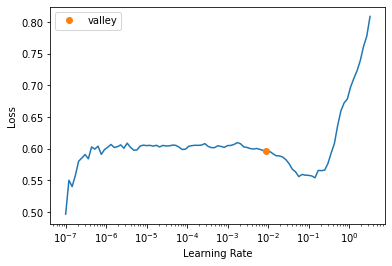

In [517]:
learn.lr_find()

In [518]:
learn.fit_one_cycle(4, 1e-2, wd=0.07)

epoch,train_loss,valid_loss,time
0,0.601995,0.580977,00:00
1,0.512843,0.447811,00:00
2,0.426090,0.438656,00:00
3,0.367786,0.430589,00:00


# Same model plus user budget and place price

In [519]:
up_df = pd.read_csv(data_folder/"userprofile.csv", header=0)
up_df.columns

Index(['userID', 'latitude', 'longitude', 'smoker', 'drink_level',
       'dress_preference', 'ambience', 'transport', 'marital_status', 'hijos',
       'birth_year', 'interest', 'personality', 'religion', 'activity',
       'color', 'weight', 'budget', 'height'],
      dtype='object')

In [520]:

budget = up_df[["userID", "budget"]]
budget.head()

,userID,budget
0,U1001,medium
1,U1002,low
2,U1003,low
3,U1004,medium
4,U1005,medium


In [521]:
gp_df = pd.read_csv(data_folder/"geoplaces2.csv", encoding="cp1252", header=0)
gp_df,

(     placeID   latitude   longitude  \
 0     134999  18.915421  -99.184871   
 1     132825  22.147392 -100.983092   
 2     135106  22.149709 -100.976093   
 3     132667  23.752697  -99.163359   
 4     132613  23.752903  -99.165076   
 ..       ...        ...         ...   
 125   132866  22.141220 -100.931311   
 126   135072  22.149192 -101.002936   
 127   135109  18.921785  -99.235350   
 128   135019  18.875011  -99.159422   
 129   132877  22.135364 -100.934948   
 
                                          the_geom_meter  \
 0    0101000020957F000088568DE356715AC138C0A525FC464A41   
 1    0101000020957F00001AD016568C4858C1243261274BA54B41   
 2    0101000020957F0000649D6F21634858C119AE9BF528A34B41   
 3    0101000020957F00005D67BCDDED8157C1222A2DC8D84D4941   
 4    0101000020957F00008EBA2D06DC8157C194E03B7B504E4941   
 ..                                                  ...   
 125  0101000020957F000013871838EC4A58C1B5DF74F8E3964B41   
 126  0101000020957F0000E7B79B1DB94758

In [522]:

prices = gp_df[["placeID","price"]]
prices.value_counts()

placeID  price 
132560   low       1
135051   low       1
135049   medium    1
135048   high      1
135047   high      1
                  ..
132854   medium    1
132851   low       1
132847   low       1
132846   low       1
135109   medium    1
Length: 130, dtype: int64

In [523]:
ratings = df.merge(prices, left_on="place", right_on="placeID")
ratings

,user,place,rating,placeID,price
0,U1077,135085,2,135085,medium
1,U1108,135085,1,135085,medium
2,U1081,135085,1,135085,medium
3,U1056,135085,2,135085,medium
4,U1134,135085,2,135085,medium
...,...,...,...,...,...
1156,U1061,132958,2,132958,low
1157,U1025,132958,1,132958,low
1158,U1097,132958,2,132958,low
1159,U1096,132958,1,132958,low


In [524]:
ratings = ratings.merge(budget, left_on="user", right_on="userID")
ratings

,user,place,rating,placeID,price,userID,budget
0,U1077,135085,2,135085,medium,U1077,medium
1,U1077,135038,2,135038,medium,U1077,medium
2,U1077,132825,2,132825,low,U1077,medium
3,U1077,135060,1,135060,medium,U1077,medium
4,U1077,135027,0,135027,medium,U1077,medium
...,...,...,...,...,...,...,...
1156,U1047,132877,0,132877,low,U1047,medium
1157,U1047,132884,0,132884,low,U1047,medium
1158,U1138,132921,2,132921,low,U1138,medium
1159,U1138,132922,2,132922,medium,U1138,medium


## Train simple model with two categorical features

In [525]:
ratings.columns

Index(['user', 'place', 'rating', 'placeID', 'price', 'userID', 'budget'], dtype='object')

In [526]:
# Restore the original budget and price columns.
ratings = (
    df.merge(gp_df, left_on="place", right_on="placeID")
      .merge(up_df, left_on="user", right_on="userID")
)

ratings = ratings[
    ["user", "place", "budget", "price", "rating"]
].copy()

splits = RandomSplitter(valid_pct=0.2, seed=42)(range_of(ratings))

to = TabularCollab(
    ratings,
    procs=[Categorify],
    cat_names=["user", "place", "budget", "price"], 
    y_names=["rating"],
    y_block=TransformBlock(),
    splits=splits,
)

dls = to.dataloaders(bs=64)
dls.show_batch()

,user,place,budget,price,rating
0,U1103,132667,medium,low,1
1,U1093,132767,medium,medium,2
2,U1122,135058,?,medium,2
3,U1088,135054,medium,high,2
4,U1022,135038,medium,medium,2
5,U1014,135070,medium,medium,2
6,U1014,135042,medium,medium,1
7,U1028,132740,medium,low,1
8,U1101,135027,low,medium,2
9,U1102,132854,low,medium,2


In [527]:
emb = get_emb_sz(dls)
emb

[(139, 25), (131, 25), (5, 4), (4, 3)]

In [528]:
class CollabContext(Module):
    def __init__(self, user_sz, item_sz, budget_sz, price_sz, y_range=(0, 2.5), n_act=25):
        self.user_factors = Embedding(*user_sz)
        self.item_factors = Embedding(*item_sz)
        self.budget_factors = Embedding(*budget_sz)
        self.price_factors = Embedding(*price_sz)
        self.layers = nn.Sequential(
            nn.Linear((user_sz[1] + item_sz[1] + budget_sz[1] + price_sz[1]), n_act),
            nn.ReLU(),
            nn.Linear(n_act, 1)
        )
        self.y_range = y_range
        
    def forward(self, x):
        users = self.user_factors(x[:,0])
        items = self.item_factors(x[:,1])
        budget = self.budget_factors(x[:,2])
        price = self.price_factors(x[:,3])
        fs = torch.cat((users, items, budget, price), dim=1)
        x = self.layers(fs)
        return sigmoid_range(x, *self.y_range)

In [529]:
model = CollabContext(*emb)

In [530]:
learn = Learner(dls, model, loss_func=MSELossFlat())

SuggestedLRs(valley=0.013182567432522774)

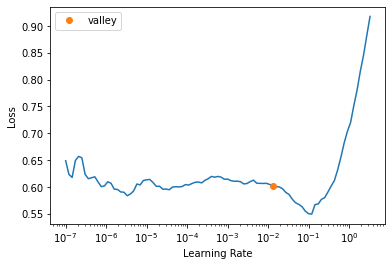

In [531]:
learn.lr_find()

In [532]:
learn.fit_one_cycle(4, 1e-2, wd=0.07)

epoch,train_loss,valid_loss,time
0,0.607438,0.621623,00:00
1,0.526833,0.466092,00:00
2,0.431704,0.491232,00:00
3,0.367928,0.483004,00:00
